# Fraud Detection System using Machine Learning

### Objective

The goal of this project is to develop a machine learning model capable of identifying fraudulent credit card transactions. Since fraudulent transactions are extremely rare compared to legitimate ones, this is considered an imbalanced classification problem.

### Project Workflow

- Data Collection
- Exploratory Data Analysis
- Data Preprocessing
- Feature Engineering
- Handling Imbalanced Data
- Model Building
- Model Evaluation
- Model Saving

In [158]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE

import joblib

# Load Dataset

The dataset contains anonymized credit card transactions. The target variable is **Class**, where:

- 0 → Legitimate Transaction
- 1 → Fraudulent Transaction

In [159]:
df = pd.read_csv("../data/creditcard.csv")

In [160]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [161]:
df.shape

(284807, 31)

In [162]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [163]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


# Missing Values

In [164]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

# Fraud distribution

In [165]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

# 📊 Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the structure of the dataset, identify patterns, detect anomalies, and gain insights before building machine learning models.

In this project, we analyze:
- Class distribution
- Fraud percentage
- Transaction amount distribution
- Transaction time distribution
- Amount comparison between fraud and non-fraud
- Correlation between features

In [166]:
import os

IMAGE_DIR = "../images"

os.makedirs(IMAGE_DIR, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGE_DIR, filename),
                dpi=300,
                bbox_inches="tight")
    plt.show()

## 1. Class Distribution

This visualization shows the number of fraudulent and non-fraudulent transactions.

Since fraudulent transactions are extremely rare compared to normal transactions, the dataset is highly imbalanced. This imbalance can bias machine learning models toward predicting the majority class.

Therefore, techniques such as SMOTE will later be applied to balance the training data.

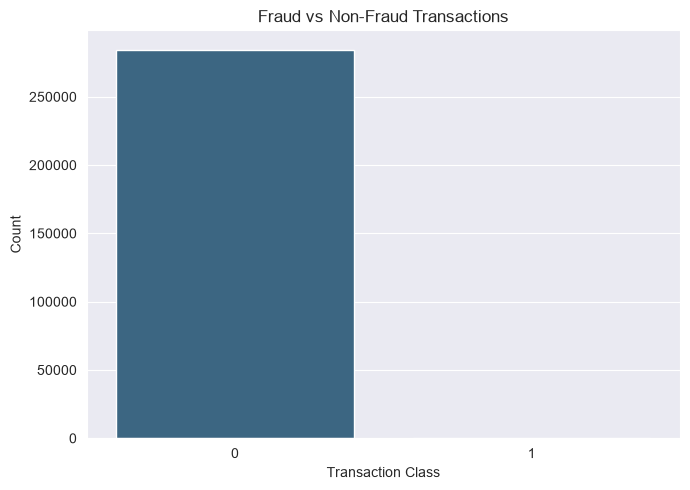

In [167]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Class", palette="viridis")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Count")

save_plot("01_class_distribution.png")

## 2. Fraud Percentage

This section calculates the percentage of fraudulent and legitimate transactions.

It provides a clearer understanding of the imbalance present in the dataset.

In [168]:
fraud_percentage = df["Class"].value_counts(normalize=True) * 100

print(f"Non-Fraud : {fraud_percentage[0]:.2f}%")
print(f"Fraud     : {fraud_percentage[1]:.2f}%")

Non-Fraud : 99.83%
Fraud     : 0.17%


## 3. Transaction Amount Distribution

This histogram shows how transaction amounts are distributed.

Most transactions occur at lower amounts, while only a few transactions involve very large values. This indicates a positively skewed distribution.

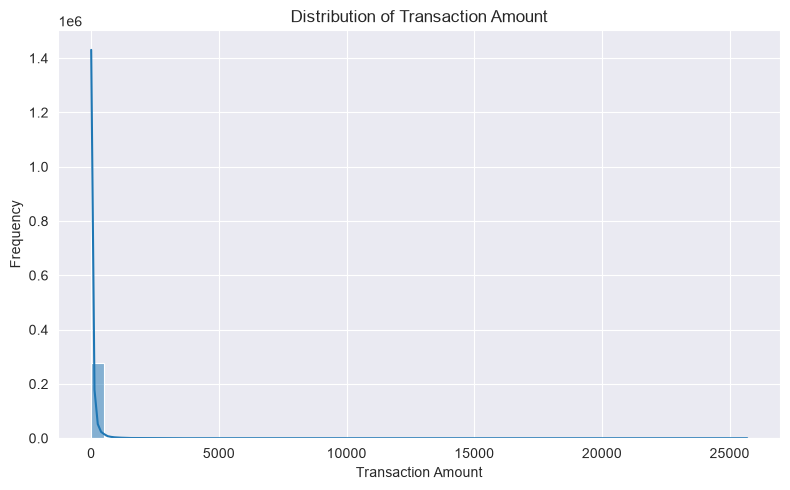

In [169]:
plt.figure(figsize=(8,5))

sns.histplot(df["Amount"], bins=50, kde=True)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

save_plot("02_amount_distribution.png")

## 4. Transaction Time Distribution

The dataset records the elapsed time from the first transaction.

This visualization helps identify periods with higher transaction activity.

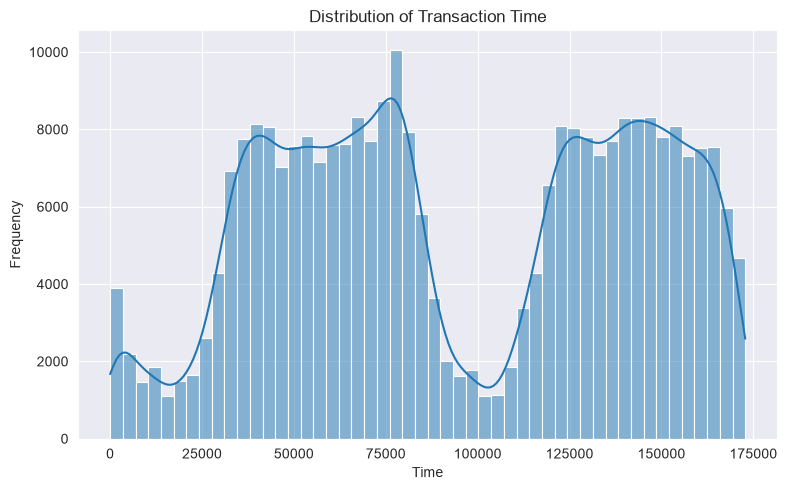

In [170]:
plt.figure(figsize=(8,5))

sns.histplot(df["Time"], bins=50, kde=True)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time")
plt.ylabel("Frequency")

save_plot("03_time_distribution.png")

## 5. Transaction Amount by Class

A boxplot compares transaction amounts for fraudulent and non-fraudulent transactions.

It helps identify differences in transaction value distributions and potential outliers.

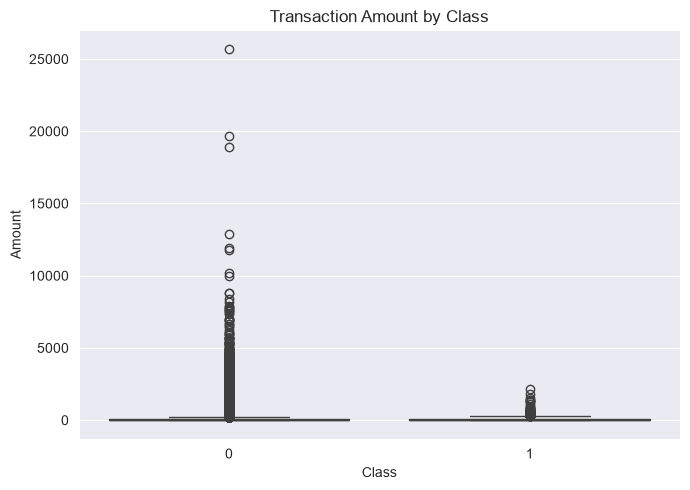

In [171]:
plt.figure(figsize=(7,5))

sns.boxplot(data=df,
            x="Class",
            y="Amount")

plt.title("Transaction Amount by Class")
plt.xlabel("Class")
plt.ylabel("Amount")

save_plot("04_boxplot_amount_class.png")

## 6. Correlation Heatmap

The heatmap visualizes the correlation between all numerical features.

Features with stronger positive or negative correlation with the target variable may be more useful for fraud detection.

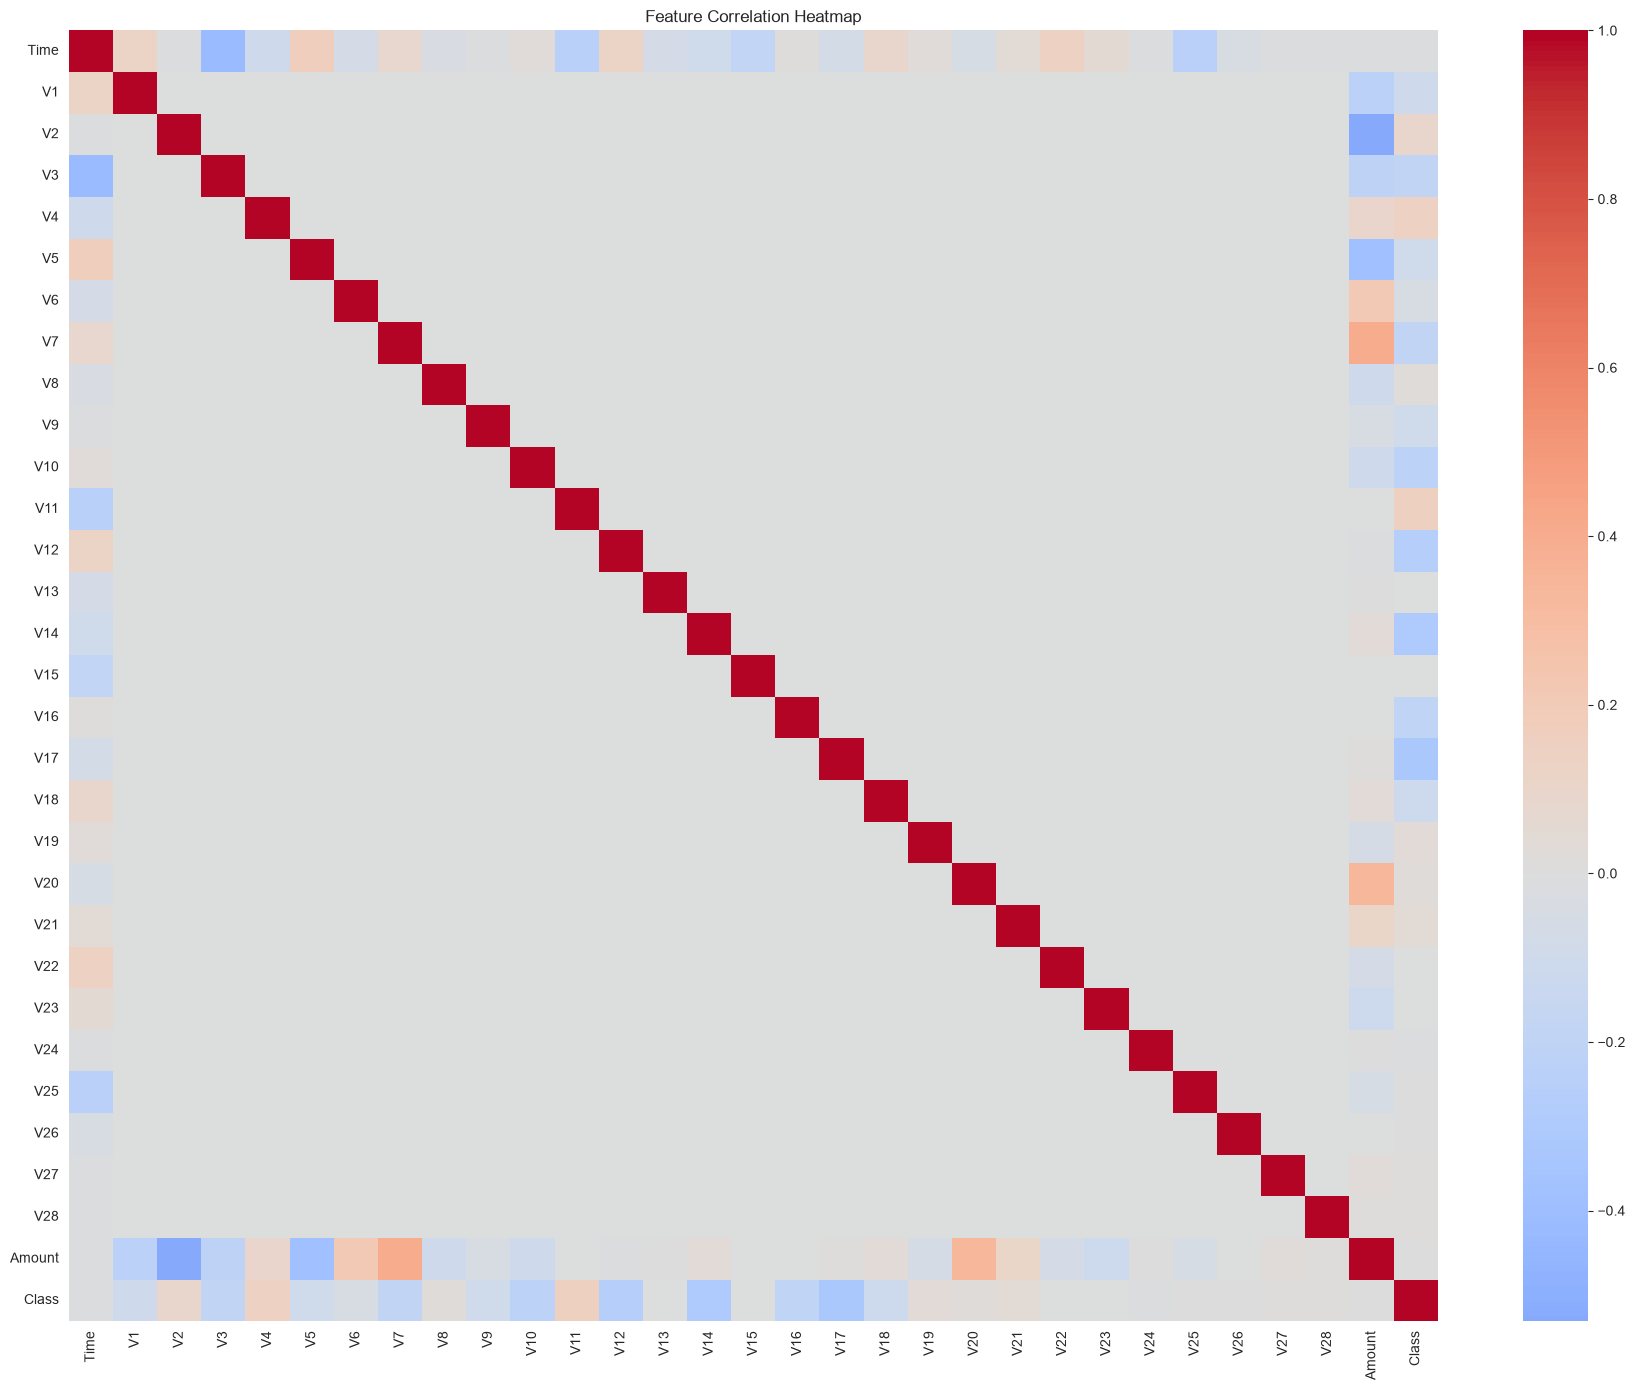

In [172]:
plt.figure(figsize=(18,14))

sns.heatmap(df.corr(),
            cmap="coolwarm",
            center=0)

plt.title("Feature Correlation Heatmap")

save_plot("05_correlation_heatmap.png")

## 7. Features Most Correlated with Fraud

This analysis identifies the features with the strongest positive and negative correlations with the target variable (`Class`).

These features are likely to contribute significantly to the predictive model.

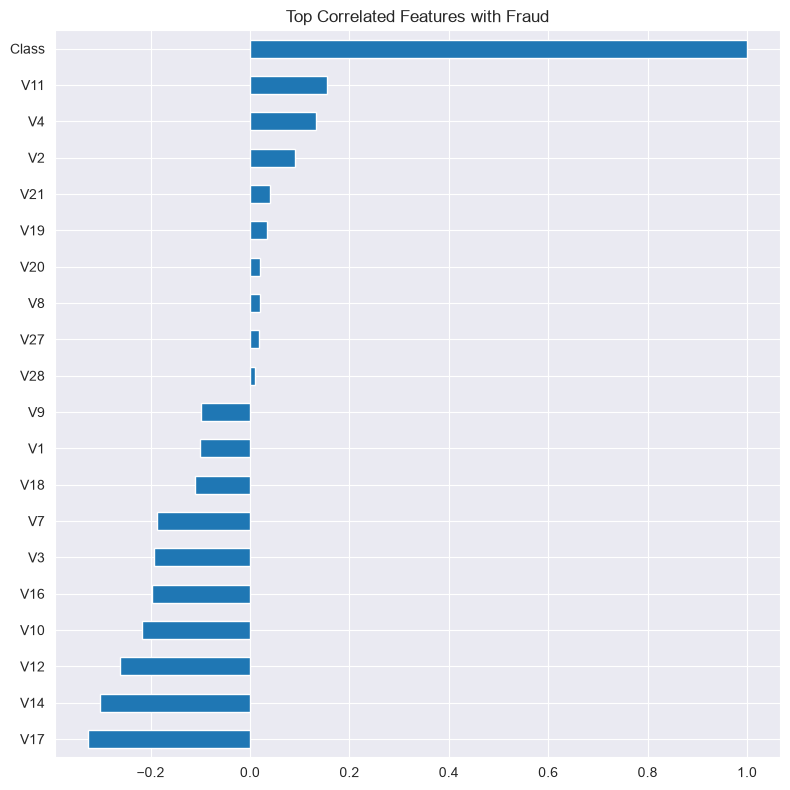

In [173]:
corr = df.corr()["Class"].sort_values()

top_corr = pd.concat([corr.head(10), corr.tail(10)])

plt.figure(figsize=(8,8))

top_corr.plot(kind="barh")

plt.title("Top Correlated Features with Fraud")

save_plot("06_top_correlated_features.png")

# Data Preprocessing

The preprocessing stage prepares the dataset for machine learning by:

- Removing unnecessary data
- Scaling numerical features
- Separating features and target variable

In [174]:
X = df.drop("Class", axis=1).copy()
y = df["Class"].copy()

In [175]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop("Class", axis=1).copy()
y = df["Class"].copy()

# Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale Amount using only the training data
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["scaled_amount"] = scaler.fit_transform(
    X_train[["Amount"]]
)

X_test["scaled_amount"] = scaler.transform(
    X_test[["Amount"]]
)

# Remove the original Amount column
X_train.drop("Amount", axis=1, inplace=True)
X_test.drop("Amount", axis=1, inplace=True)

# Keep the same feature order in training and testing
X_test = X_test[X_train.columns]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Preprocessing completed successfully!")


Training data shape: (227845, 30)
Testing data shape: (56962, 30)
Preprocessing completed successfully!


In [176]:
print(X_train.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'scaled_amount']


# Scale Amount

In [177]:
# Data Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Start from the original dataset
X = df.drop("Class", axis=1).copy()
y = df["Class"].copy()

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale Amount
scaler = StandardScaler()

X_train["scaled_amount"] = scaler.fit_transform(
    X_train[["Amount"]]
)

X_test["scaled_amount"] = scaler.transform(
    X_test[["Amount"]]
)

# Remove original Amount column
X_train.drop("Amount", axis=1, inplace=True)
X_test.drop("Amount", axis=1, inplace=True)

# Ensure same feature order
X_test = X_test[X_train.columns]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Preprocessing completed!")

Training shape: (227845, 30)
Testing shape: (56962, 30)
Preprocessing completed!


# Feature Engineering

Feature engineering improves the predictive power of machine learning models.

In this dataset:
The Amount feature is standardized using StandardScaler.

- The scaler is fitted only on the training data to prevent data leakage.
- The same fitted scaler is then applied to the testing data.
- The original Amount column is replaced with scaled_amount.
- The Time feature is retained in its original form.

# Feature Selection

The dataset already contains relevant features after PCA transformation.

Therefore, all available features are retained for model training.

# Data Splitting

In [178]:
# Save original training data for overfitting comparison

X_train.to_csv("../data/X_train.csv", index=False)

y_train.to_frame(name="Class").to_csv(
    "../data/y_train.csv", index=False
)

print("Training data saved successfully!")

Training data saved successfully!


# Handling Imbalanced Dataset

Fraudulent transactions represent less than 1% of the total observations.

To balance the training dataset, Synthetic Minority Oversampling Technique (SMOTE) is applied.

In [179]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

# Apply SMOTE only to the training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nOriginal training shape:", X_train.shape)
print("Balanced training shape:", X_train_smote.shape)
print("Testing shape:", X_test.shape)


Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Original training shape: (227845, 30)
Balanced training shape: (454902, 30)
Testing shape: (56962, 30)


# Model Building

In this section, multiple machine learning models are trained and evaluated to identify the best-performing model for detecting fraudulent transactions.

The following algorithms are used:

- Logistic Regression
- Random Forest Classifier

The models are compared using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC Score

# Model 1: Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for binary classification problems. It predicts the probability that a transaction is fraudulent or legitimate.

Advantages:
- Fast to train
- Easy to interpret
- Good baseline model

In [180]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_smote, y_train_smote)

logistic_prediction = logistic_model.predict(X_test)

logistic_probability = logistic_model.predict_proba(X_test)[:,1]

# Logistic Regression Evaluation

The model is evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

In [181]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :",accuracy_score(y_test,logistic_prediction))

print("Precision :",precision_score(y_test,logistic_prediction))

print("Recall :",recall_score(y_test,logistic_prediction))

print("F1 Score :",f1_score(y_test,logistic_prediction))

print("ROC AUC :",roc_auc_score(y_test,logistic_probability))

print("\nClassification Report\n")

print(classification_report(y_test,logistic_prediction))

Accuracy : 0.9882904392401952
Precision : 0.11914323962516733
Recall : 0.9081632653061225
F1 Score : 0.2106508875739645
ROC AUC : 0.9756127760614657

Classification Report

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.91      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.95      0.60     56962
weighted avg       1.00      0.99      0.99     56962



In [182]:
results = []

In [183]:
results.append({

    "Model":"Logistic Regression",

    "Accuracy":accuracy_score(y_test,logistic_prediction),

    "Precision":precision_score(y_test,logistic_prediction),

    "Recall":recall_score(y_test,logistic_prediction),

    "F1 Score":f1_score(y_test,logistic_prediction),

    "ROC AUC":roc_auc_score(y_test,logistic_probability)

})

## Confusion Matrix


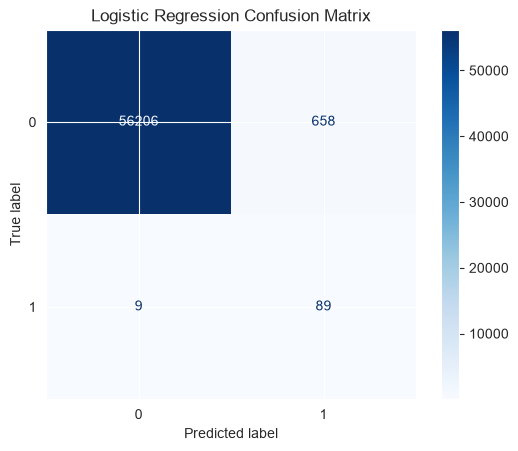

In [184]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_prediction,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.show()

## ROC Curve

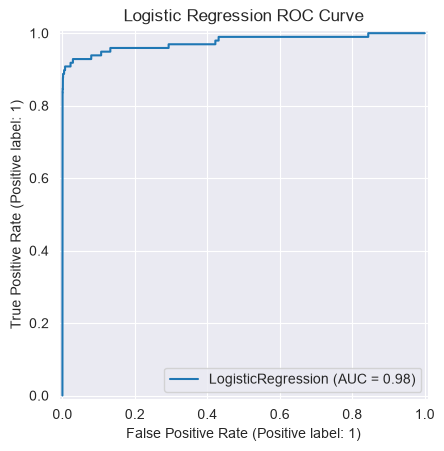

In [185]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("Logistic Regression ROC Curve")

plt.show()

## Observation

Logistic Regression serves as the baseline model. The obtained metrics will be compared with more advanced machine learning algorithms.

# Model 2: Decision Tree

Decision Trees classify data by recursively splitting features into decision nodes.

Advantages

- Easy to visualize
- Captures non-linear relationships
- Requires little preprocessing

In [186]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(

    random_state=42,

    max_depth=10

)

dt_model.fit(
X_train_smote, y_train_smote

)

dt_prediction = dt_model.predict(

    X_test

)

dt_probability = dt_model.predict_proba(

    X_test

)[:,1]

## Evaluation

In [187]:
print("Accuracy :",accuracy_score(y_test,dt_prediction))

print("Precision :",precision_score(y_test,dt_prediction))

print("Recall :",recall_score(y_test,dt_prediction))

print("F1 Score :",f1_score(y_test,dt_prediction))

print("ROC AUC :",roc_auc_score(y_test,dt_probability))

print(classification_report(y_test,dt_prediction))

Accuracy : 0.9859028826235033
Precision : 0.09621993127147767
Recall : 0.8571428571428571
F1 Score : 0.17301750772399588
ROC AUC : 0.9205093176128077
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.10      0.86      0.17        98

    accuracy                           0.99     56962
   macro avg       0.55      0.92      0.58     56962
weighted avg       1.00      0.99      0.99     56962



In [188]:
results.append({

    "Model":"Decision Tree",

    "Accuracy":accuracy_score(y_test,dt_prediction),

    "Precision":precision_score(y_test,dt_prediction),

    "Recall":recall_score(y_test,dt_prediction),

    "F1 Score":f1_score(y_test,dt_prediction),

    "ROC AUC":roc_auc_score(y_test,dt_probability)

})

## Confusion matrix

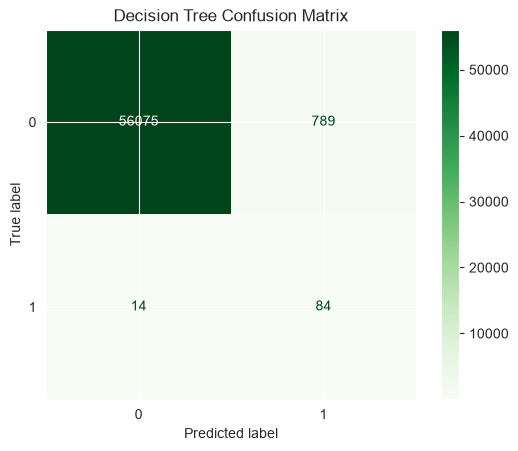

In [189]:
ConfusionMatrixDisplay.from_predictions(

    y_test,

    dt_prediction,

    cmap="Greens"

)

plt.title("Decision Tree Confusion Matrix")

plt.show()

## ROC Curve

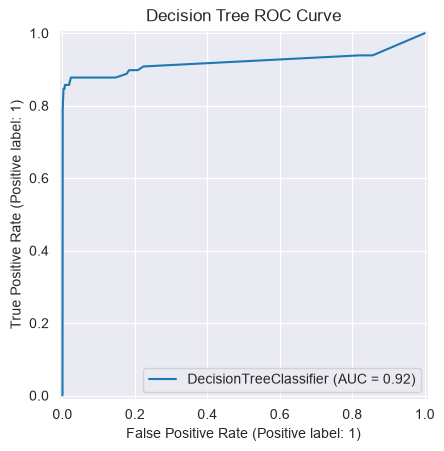

In [190]:
RocCurveDisplay.from_estimator(

    dt_model,

    X_test,

    y_test

)

plt.title("Decision Tree ROC Curve")

plt.show()

## Feature Importance

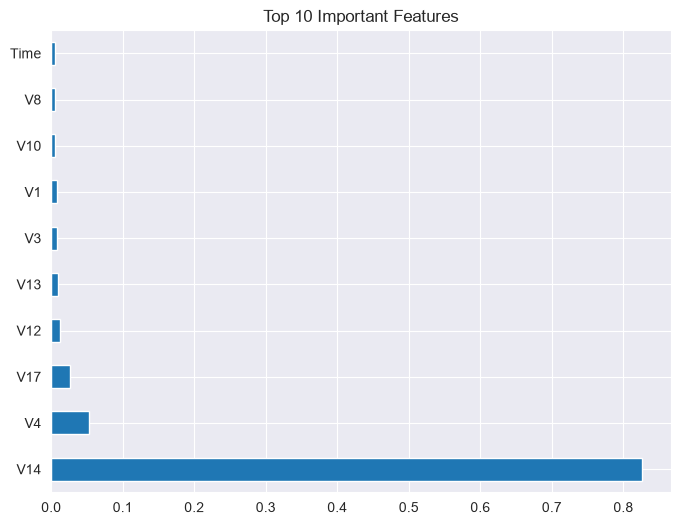

In [191]:
importance = pd.Series(

    dt_model.feature_importances_,

    index=X.columns

)

importance = importance.sort_values(

    ascending=False

)

plt.figure(figsize=(8,6))

importance.head(10).plot(

    kind="barh"

)

plt.title("Top 10 Important Features")

plt.show()

## Store Results


# Model 3: Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve prediction accuracy and reduce overfitting.

### Advantages
- Handles imbalanced datasets effectively
- Reduces overfitting
- Provides feature importance
- High accuracy on classification problems


In [192]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_smote, y_train_smote)

rf_prediction = rf_model.predict(X_test)

rf_probability = rf_model.predict_proba(X_test)[:, 1]

## Evaluation

In [193]:
print("="*50)
print("Random Forest Performance")
print("="*50)

print("Accuracy :", accuracy_score(y_test, rf_prediction))
print("Precision :", precision_score(y_test, rf_prediction))
print("Recall :", recall_score(y_test, rf_prediction))
print("F1 Score :", f1_score(y_test, rf_prediction))
print("ROC AUC :", roc_auc_score(y_test, rf_probability))

print("\nClassification Report\n")
print(classification_report(y_test, rf_prediction))

Random Forest Performance
Accuracy : 0.9990871107053826
Precision : 0.6916666666666667
Recall : 0.8469387755102041
F1 Score : 0.7614678899082569
ROC AUC : 0.9774806412435544

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.69      0.85      0.76        98

    accuracy                           1.00     56962
   macro avg       0.85      0.92      0.88     56962
weighted avg       1.00      1.00      1.00     56962



## Confusion Matrix


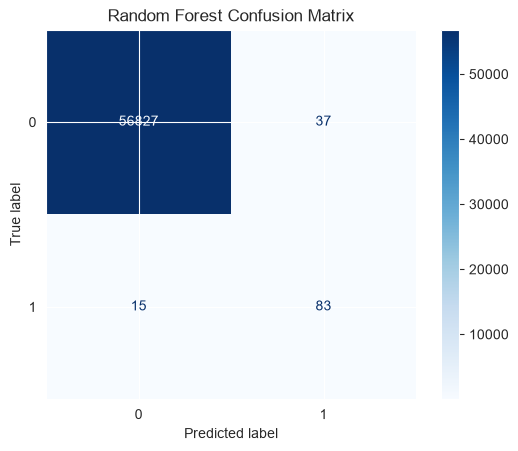

In [194]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_prediction,
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

## ROC Curve

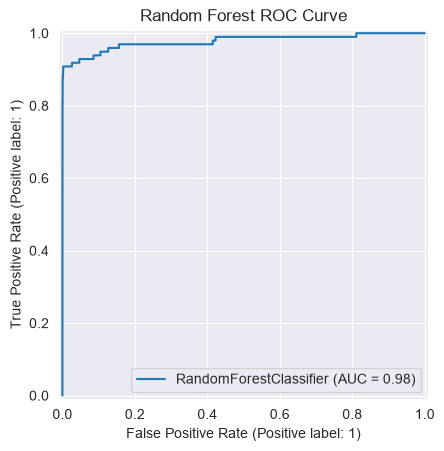

In [195]:
RocCurveDisplay.from_estimator(
    rf_model,
    X_test,
    y_test
)

plt.title("Random Forest ROC Curve")
plt.show()

## Feature Importance

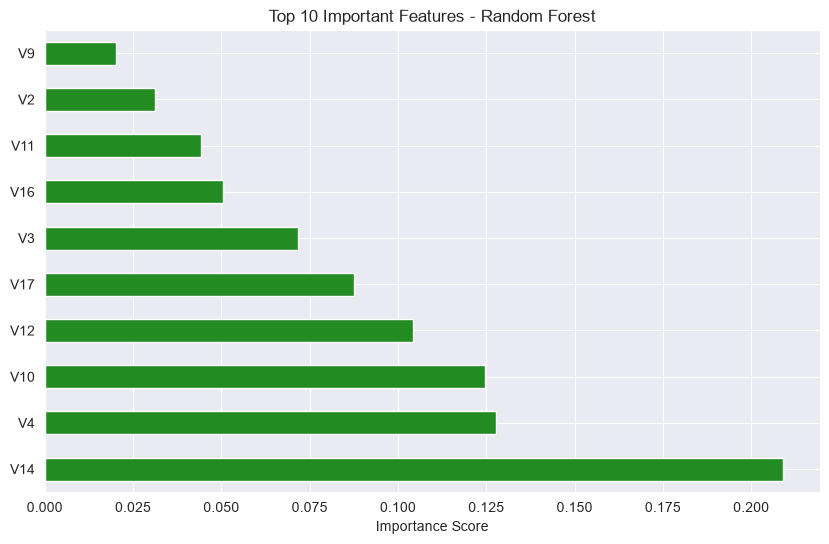

In [196]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

plt.figure(figsize=(10,6))

feature_importance.head(10).plot(
    kind="barh",
    color="forestgreen"
)

plt.title("Top 10 Important Features - Random Forest")

plt.xlabel("Importance Score")

plt.show()

## Metrics

In [197]:
results.append({

    "Model":"Random Forest",

    "Accuracy":accuracy_score(y_test,rf_prediction),

    "Precision":precision_score(y_test,rf_prediction),

    "Recall":recall_score(y_test,rf_prediction),

    "F1 Score":f1_score(y_test,rf_prediction),

    "ROC AUC":roc_auc_score(y_test,rf_probability)

})

# Model 4: Extra Trees Classifier

Extra Trees (Extremely Randomized Trees) is an ensemble learning algorithm similar to Random Forest.

Unlike Random Forest, Extra Trees introduces more randomness while building trees, often improving generalization performance.

In [198]:
from sklearn.ensemble import ExtraTreesClassifier

et_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train_smote, y_train_smote)

et_prediction = et_model.predict(X_test)

et_probability = et_model.predict_proba(X_test)[:,1]

## Evaluation

In [199]:
print("="*50)
print("Extra Trees Performance")
print("="*50)

print("Accuracy :", accuracy_score(y_test, et_prediction))
print("Precision :", precision_score(y_test, et_prediction))
print("Recall :", recall_score(y_test, et_prediction))
print("F1 Score :", f1_score(y_test, et_prediction))
print("ROC AUC :", roc_auc_score(y_test, et_probability))

print("\nClassification Report\n")
print(classification_report(y_test, et_prediction))

Extra Trees Performance
Accuracy : 0.9989642217618764
Precision : 0.6466165413533834
Recall : 0.8775510204081632
F1 Score : 0.7445887445887446
ROC AUC : 0.9834765082172429

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.65      0.88      0.74        98

    accuracy                           1.00     56962
   macro avg       0.82      0.94      0.87     56962
weighted avg       1.00      1.00      1.00     56962



## Confusion Matrix

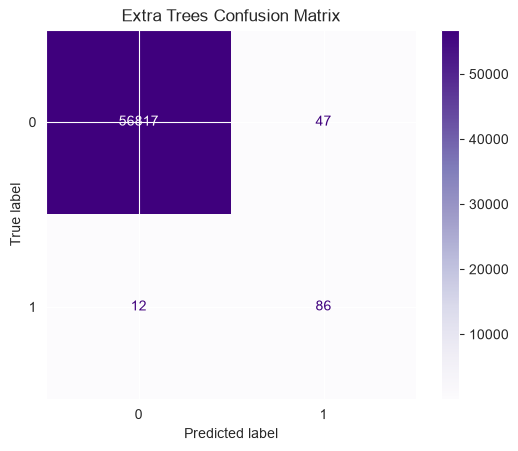

In [200]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    et_prediction,
    cmap="Purples"
)

plt.title("Extra Trees Confusion Matrix")

plt.show()

## ROC Curve

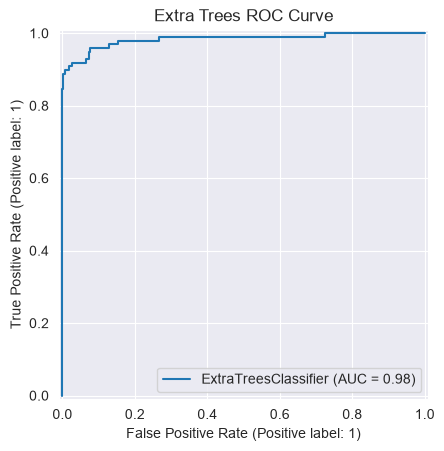

In [201]:
RocCurveDisplay.from_estimator(
    et_model,
    X_test,
    y_test
)

plt.title("Extra Trees ROC Curve")

plt.show()

## Feature Importance

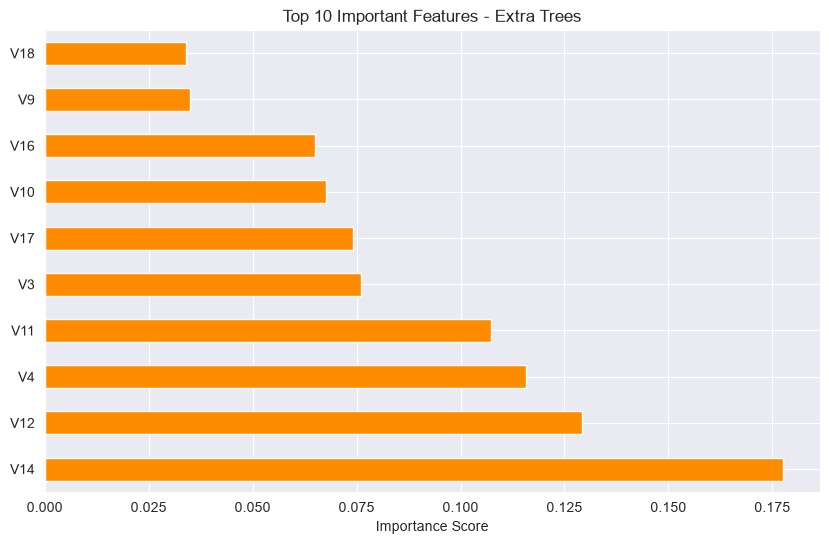

In [202]:
feature_importance = pd.Series(
    et_model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

plt.figure(figsize=(10,6))

feature_importance.head(10).plot(
    kind="barh",
    color="darkorange"
)

plt.title("Top 10 Important Features - Extra Trees")

plt.xlabel("Importance Score")

plt.show()

## Metrics

In [203]:
results.append({

    "Model":"Extra Trees",

    "Accuracy":accuracy_score(y_test,et_prediction),

    "Precision":precision_score(y_test,et_prediction),

    "Recall":recall_score(y_test,et_prediction),

    "F1 Score":f1_score(y_test,et_prediction),

    "ROC AUC":roc_auc_score(y_test,et_probability)

})

# Model 5: XGBoost Classifier

Extreme Gradient Boosting (XGBoost) is one of the most powerful ensemble machine learning algorithms for structured/tabular datasets.

### Advantages
- Excellent performance on imbalanced datasets
- Fast and efficient
- Handles complex feature interactions
- Widely used in fraud detection, banking, and Kaggle competitions

In [204]:
from xgboost import XGBClassifier

In [205]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_smote, y_train_smote)

print("XGBoost training completed!")

XGBoost training completed!


In [206]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predictions on unseen testing data

y_pred_v2 = xgb_model.predict(X_test)
y_prob_v2 = xgb_model.predict_proba(X_test)[:, 1]

# Create consistent variable names for later evaluation
xgb_prediction = y_pred_v2
xgb_probability = y_prob_v2

print("XGBoost predictions generated successfully!")

print("\nXGBoost Performance")
print("----------------------------")

print("Accuracy:", accuracy_score(y_test, xgb_prediction))
print("Precision:", precision_score(y_test, xgb_prediction))
print("Recall:", recall_score(y_test, xgb_prediction))
print("F1 Score:", f1_score(y_test, xgb_prediction))
print("ROC-AUC:", roc_auc_score(y_test, xgb_probability))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_prediction))

print("\nClassification Report:")
print(classification_report(y_test, xgb_prediction))


XGBoost predictions generated successfully!

XGBoost Performance
----------------------------
Accuracy: 0.9971033320459254
Precision: 0.3598326359832636
Recall: 0.8775510204081632
F1 Score: 0.5103857566765578
ROC-AUC: 0.9820123990789338

Confusion Matrix:
[[56711   153]
 [   12    86]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.36      0.88      0.51        98

    accuracy                           1.00     56962
   macro avg       0.68      0.94      0.75     56962
weighted avg       1.00      1.00      1.00     56962



In [207]:
train_pred_v2 = xgb_model.predict(X_train_smote)
train_prob_v2 = xgb_model.predict_proba(X_train_smote)[:, 1]

print("TRAINING PERFORMANCE")
print("--------------------")
print("Accuracy:", accuracy_score(y_train_smote, train_pred_v2))
print("Precision:", precision_score(y_train_smote, train_pred_v2))
print("Recall:", recall_score(y_train_smote, train_pred_v2))
print("F1 Score:", f1_score(y_train_smote, train_pred_v2))
print("ROC-AUC:", roc_auc_score(y_train_smote, train_prob_v2))

TRAINING PERFORMANCE
--------------------
Accuracy: 0.9981556467107201
Precision: 0.9977945311401659
Recall: 0.9985183621966929
F1 Score: 0.9981563154436599
ROC-AUC: 0.9999535561337136


In [208]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

print("THRESHOLD COMPARISON")
print("-" * 65)

for threshold in thresholds:

    predictions = (y_prob_v2 >= threshold).astype(int)

    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

THRESHOLD COMPARISON
-----------------------------------------------------------------
Threshold: 0.30 | Precision: 0.2075 | Recall: 0.8980 | F1: 0.3372
Threshold: 0.35 | Precision: 0.2458 | Recall: 0.8878 | F1: 0.3850
Threshold: 0.40 | Precision: 0.2857 | Recall: 0.8776 | F1: 0.4311
Threshold: 0.45 | Precision: 0.3245 | Recall: 0.8776 | F1: 0.4738
Threshold: 0.50 | Precision: 0.3598 | Recall: 0.8776 | F1: 0.5104
Threshold: 0.55 | Precision: 0.3881 | Recall: 0.8673 | F1: 0.5363
Threshold: 0.60 | Precision: 0.4208 | Recall: 0.8673 | F1: 0.5667


## Evaluation

In [209]:
# XGBoost Performance (Version 2)

print("="*50)
print("XGBoost Performance - Version 2")
print("="*50)

print("Accuracy :", accuracy_score(y_test, y_pred_v2))

print("Precision :", precision_score(y_test, y_pred_v2))

print("Recall :", recall_score(y_test, y_pred_v2))

print("F1 Score :", f1_score(y_test, y_pred_v2))

print("ROC AUC :", roc_auc_score(y_test, y_prob_v2))

print("\nClassification Report\n")

print(classification_report(y_test, y_pred_v2))

XGBoost Performance - Version 2
Accuracy : 0.9971033320459254
Precision : 0.3598326359832636
Recall : 0.8775510204081632
F1 Score : 0.5103857566765578
ROC AUC : 0.9820123990789338

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.36      0.88      0.51        98

    accuracy                           1.00     56962
   macro avg       0.68      0.94      0.75     56962
weighted avg       1.00      1.00      1.00     56962



## Confusion Matrix

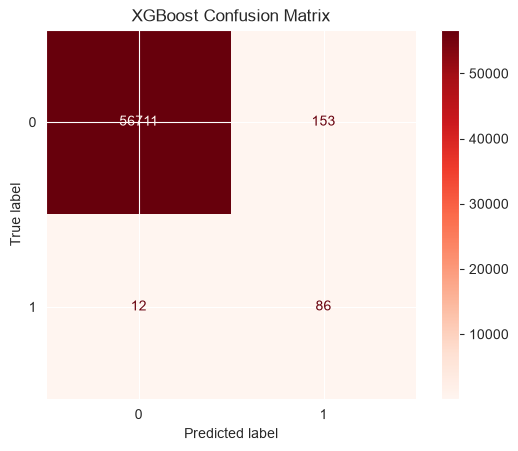

In [210]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_prediction,
    cmap="Reds"
)

plt.title("XGBoost Confusion Matrix")

plt.show()

## ROC Curve

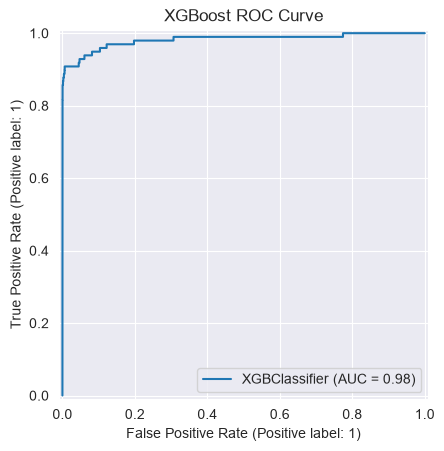

In [211]:
RocCurveDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test
)

plt.title("XGBoost ROC Curve")

plt.show()

## Feature Importance

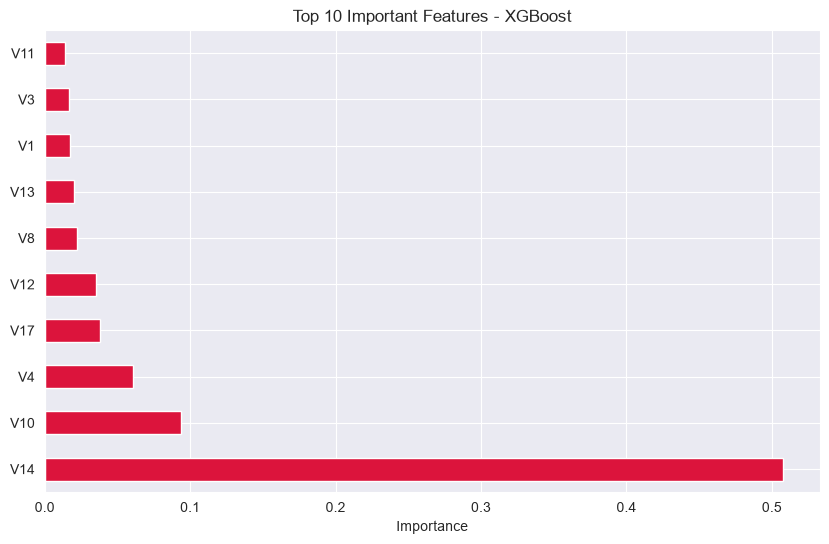

In [212]:
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

plt.figure(figsize=(10,6))

feature_importance.head(10).plot(
    kind="barh",
    color="crimson"
)

plt.title("Top 10 Important Features - XGBoost")

plt.xlabel("Importance")

plt.show()

In [213]:
results.append({

    "Model":"XGBoost",

    "Accuracy":accuracy_score(y_test,xgb_prediction),

    "Precision":precision_score(y_test,xgb_prediction),

    "Recall":recall_score(y_test,xgb_prediction),

    "F1 Score":f1_score(y_test,xgb_prediction),

    "ROC AUC":roc_auc_score(y_test,xgb_probability)

})

# Model 6: Isolation Forest

Isolation Forest is an unsupervised anomaly detection algorithm.

Unlike supervised learning algorithms, it identifies unusual observations by isolating anomalies rather than learning from labeled examples.

It is commonly used in fraud detection where fraudulent transactions are rare.

In [214]:
from sklearn.ensemble import IsolationForest

In [215]:
iso_model = IsolationForest(
    contamination=0.0017,
    random_state=42
)

iso_model.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.0017
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


## Prediction

In [216]:
iso_prediction = iso_model.predict(X_test)

# Convert Isolation Forest output into our dataset labels
iso_prediction = [1 if i == -1 else 0 for i in iso_prediction]

In [217]:
iso_prediction


[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


## Evaluation

In [218]:
print("="*50)
print("Isolation Forest Performance")
print("="*50)

print("Accuracy :", accuracy_score(y_test, iso_prediction))

print("Precision :", precision_score(y_test, iso_prediction))

print("Recall :", recall_score(y_test, iso_prediction))

print("F1 Score :", f1_score(y_test, iso_prediction))

print("\nClassification Report\n")

print(classification_report(y_test, iso_prediction))

Isolation Forest Performance
Accuracy : 0.9975773322565921
Precision : 0.3113207547169811
Recall : 0.336734693877551
F1 Score : 0.3235294117647059

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.31      0.34      0.32        98

    accuracy                           1.00     56962
   macro avg       0.66      0.67      0.66     56962
weighted avg       1.00      1.00      1.00     56962



## Confusion Matrix

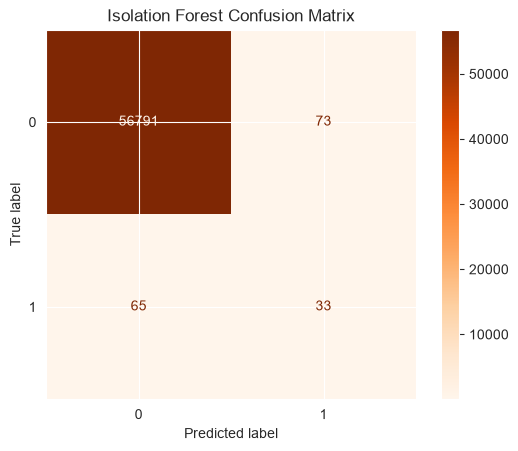

In [219]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    iso_prediction,
    cmap="Oranges"
)

plt.title("Isolation Forest Confusion Matrix")

plt.show()

In [220]:
results.append({

    "Model":"Isolation Forest",

    "Accuracy":accuracy_score(y_test,iso_prediction),

    "Precision":precision_score(y_test,iso_prediction),

    "Recall":recall_score(y_test,iso_prediction),

    "F1 Score":f1_score(y_test,iso_prediction),

    "ROC AUC":"N/A"

})

# Model Performance Comparison

This section compares the performance of all machine learning models using the following evaluation metrics:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC Score

The best-performing model is selected based on **F1 Score** and **ROC-AUC**, which are more suitable for highly imbalanced datasets like fraud detection.

In [221]:
import pandas as pd


# Final Model Performance Comparison

# Collect results from all six models
comparison = pd.DataFrame(results)

# Sort models according to F1 Score
comparison = comparison.sort_values(
    by="F1 Score",
    ascending=False
)

# Reset table index
comparison.reset_index(drop=True, inplace=True)

# Display final comparison
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 60)

comparison


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.999087,0.691667,0.846939,0.761468,0.977481
1,Extra Trees,0.998964,0.646617,0.877551,0.744589,0.983477
2,XGBoost,0.997103,0.359833,0.877551,0.510386,0.982012
3,Isolation Forest,0.997577,0.311321,0.336735,0.323529,N/A
4,Logistic Regression,0.988290,0.119143,0.908163,0.210651,0.975613
5,Decision Tree,0.985903,0.096220,0.857143,0.173018,0.920509


In [222]:
import os

# Create images folder if it doesn't exist
os.makedirs("../images", exist_ok=True)

## Bar Plot Comparison

<Figure size 1400x700 with 0 Axes>

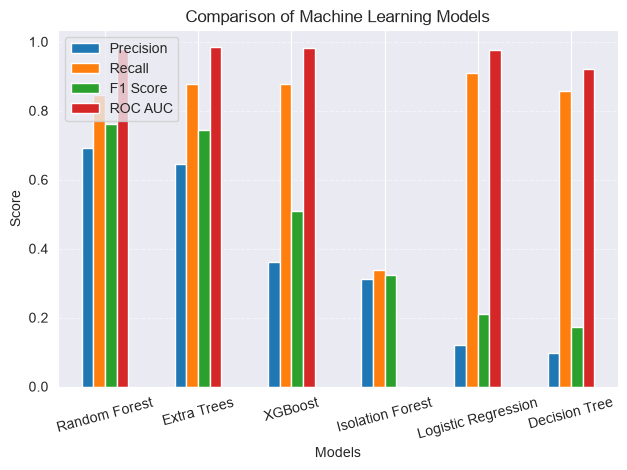

In [223]:
comparison_plot = comparison.copy()

comparison_plot["ROC AUC"] = pd.to_numeric(
    comparison_plot["ROC AUC"],
    errors="coerce"
)

plt.figure(figsize=(14,7))

comparison_plot.set_index("Model")[["Precision","Recall","F1 Score","ROC AUC"]].plot(
    kind="bar"
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("../images/model_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

## Accuracy Comparison

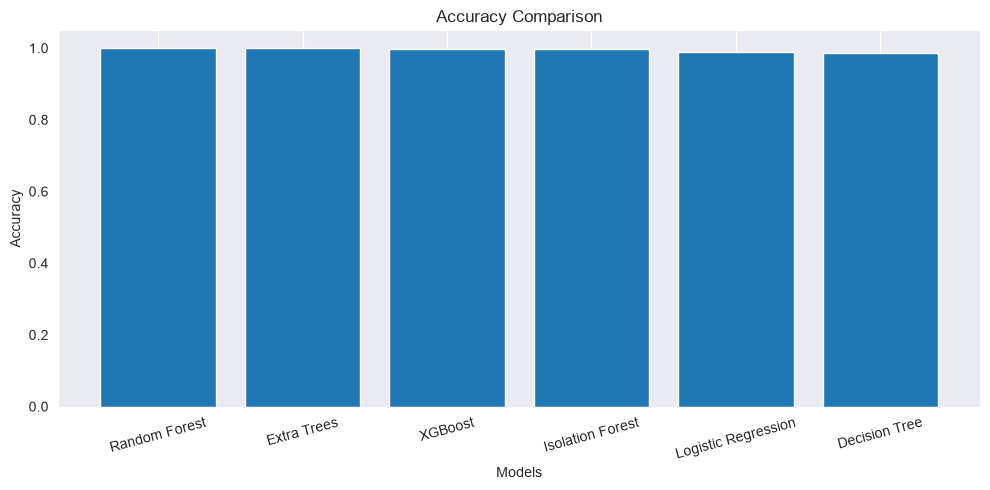

In [224]:
plt.figure(figsize=(10,5))

plt.bar(comparison["Model"], comparison["Accuracy"])

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig("../images/accuracy_comparison.png", dpi=300)

plt.show()

## Precision Comparison

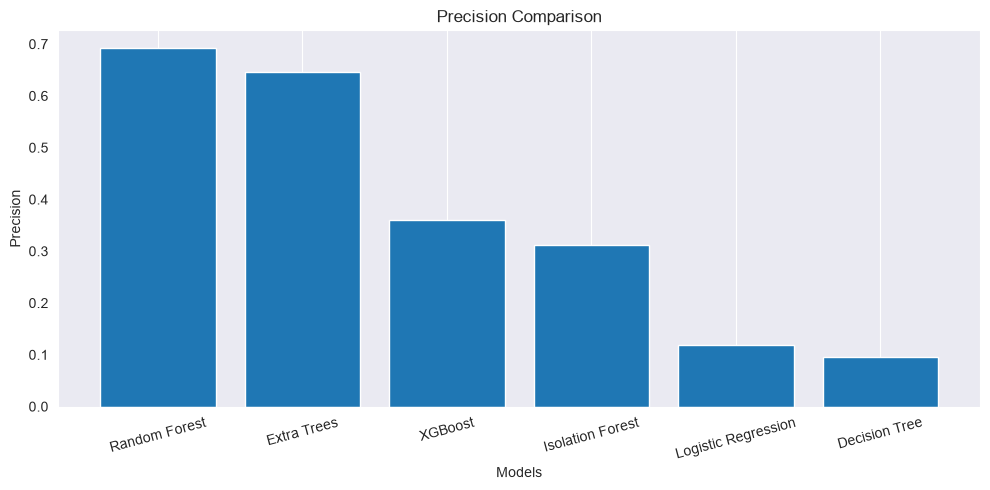

In [225]:
plt.figure(figsize=(10,5))

plt.bar(comparison["Model"], comparison["Precision"])

plt.title("Precision Comparison")
plt.ylabel("Precision")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig("../images/precision_comparison.png", dpi=300)

plt.show()

## Recall Comparison

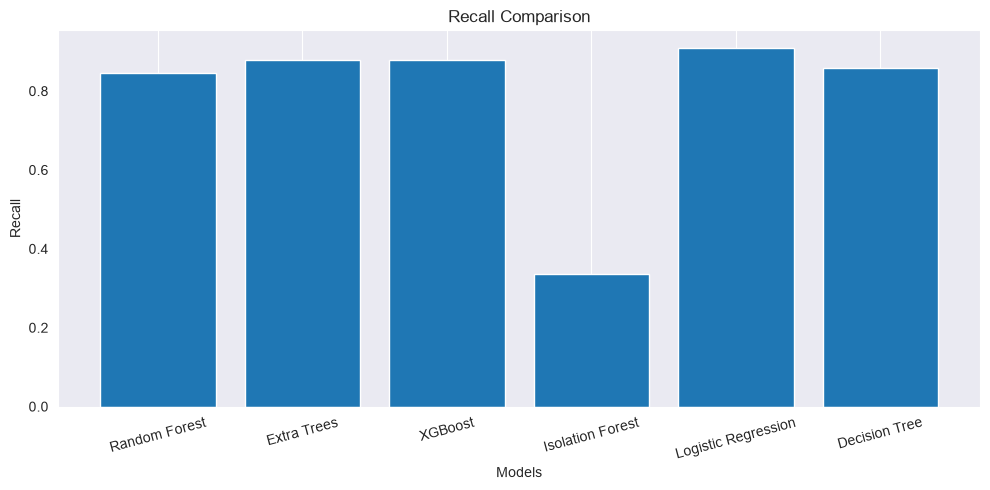

In [226]:
plt.figure(figsize=(10,5))

plt.bar(comparison["Model"], comparison["Recall"])

plt.title("Recall Comparison")
plt.ylabel("Recall")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig("../images/recall_comparison.png", dpi=300)

plt.show()

## F1-Score Comparison

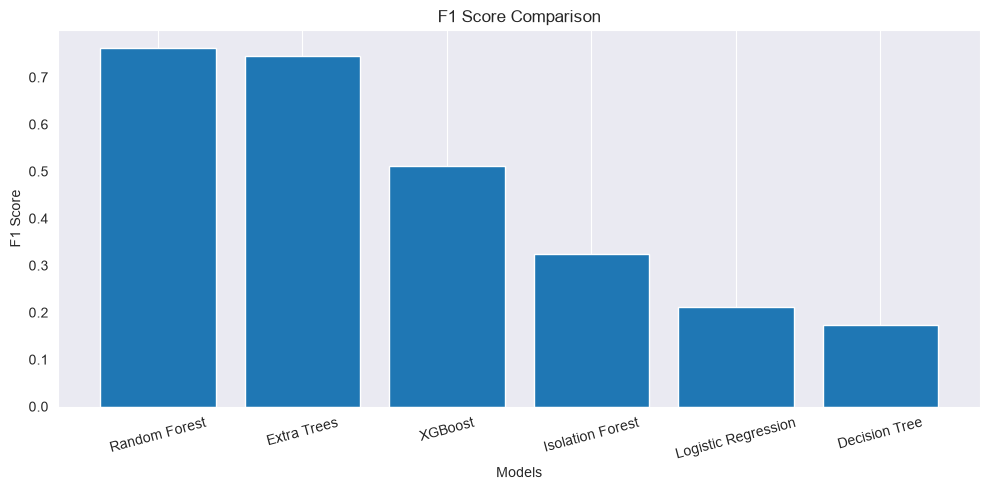

In [227]:
plt.figure(figsize=(10,5))

plt.bar(comparison["Model"], comparison["F1 Score"])

plt.title("F1 Score Comparison")
plt.ylabel("F1 Score")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig("../images/f1_score_comparison.png", dpi=300)

plt.show()

## ROC-AUC Comparison

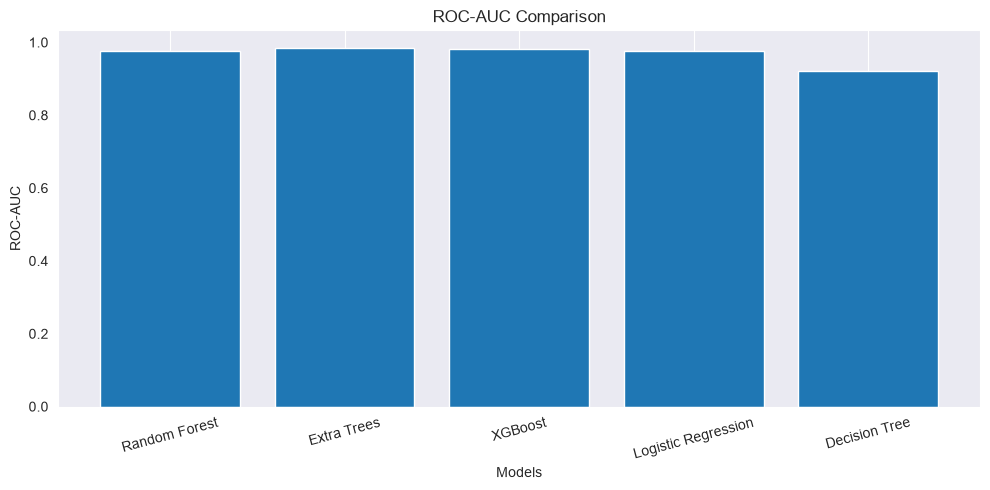

In [228]:

# ROC-AUC Comparison

# Convert ROC AUC values to numeric
roc_df = comparison.copy()

roc_df["ROC AUC"] = pd.to_numeric(
    roc_df["ROC AUC"],
    errors="coerce"
)

# Remove models where ROC-AUC is unavailable
roc_df = roc_df.dropna(subset=["ROC AUC"])

plt.figure(figsize=(10, 5))

plt.bar(roc_df["Model"], roc_df["ROC AUC"])

plt.title("ROC-AUC Comparison")
plt.ylabel("ROC-AUC")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig("../images/roc_auc_comparison.png", dpi=300)

plt.show()


In [229]:
models = {
    "Logistic Regression": logistic_prediction,
    "Decision Tree": dt_prediction,
    "Random Forest": rf_prediction,
    "Extra Trees": et_prediction,
    "XGBoost": xgb_prediction,
    "Isolation Forest": iso_prediction
}

for model_name, prediction in models.items():

    fig, ax = plt.subplots(figsize=(5,5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediction,
        cmap="Blues",
        ax=ax
    )

    plt.title(f"{model_name} Confusion Matrix")

    filename = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"../images/{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

In [230]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Extra Trees": et_model,
    "XGBoost": xgb_model
}

for model_name, model in models.items():

    fig, ax = plt.subplots(figsize=(6,6))

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax
    )

    plt.title(f"{model_name} ROC Curve")

    filename = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"../images/{filename}_roc_curve.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

In [231]:
tree_models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Extra Trees": et_model,
    "XGBoost": xgb_model
}

for model_name, model in tree_models.items():

    importance = pd.Series(
        model.feature_importances_,
        index=X.columns
    )

    importance = importance.sort_values(ascending=False)

    plt.figure(figsize=(8,6))

    importance.head(10).plot(kind="barh")

    plt.title(f"{model_name} Feature Importance")

    filename = model_name.lower().replace(" ", "_")

    plt.tight_layout()

    plt.savefig(
        f"../images/{filename}_feature_importance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

## Best Model

In [232]:
best_model = comparison.iloc[0]

print("="*50)
print("Best Performing Model")
print("="*50)

print(best_model)

Best Performing Model
Model        Random Forest
Accuracy          0.999087
Precision         0.691667
Recall            0.846939
F1 Score          0.761468
ROC AUC           0.977481
Name: 0, dtype: object


In [233]:
# Preserve the existing working Streamlit model and scaler

print("Existing fraud_detection.pkl is preserved.")
print("Existing scaler.pkl is preserved.")
print("No model or scaler will be overwritten.")

# Save test data for Streamlit evaluation
X_test.to_csv("../data/X_test.csv", index=False)

y_test.to_frame(name="Class").to_csv(
    "../data/y_test.csv",
    index=False
)

print("Test data saved successfully!")

Existing fraud_detection.pkl is preserved.
Existing scaler.pkl is preserved.
No model or scaler will be overwritten.
Test data saved successfully!


In [234]:

# Save test data for Streamlit evaluation

X_test.to_csv("../data/X_test.csv", index=False)

y_test.to_frame(name="Class").to_csv(
    "../data/y_test.csv",
    index=False
)

print("Model, scaler and test data saved successfully!")


Model, scaler and test data saved successfully!


In [235]:
print("X columns:")
print(X.columns.tolist())

print("\nX_train columns:")
print(X_train.columns.tolist())

print("\nX_test columns:")
print(X_test.columns.tolist())

X columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

X_train columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'scaled_amount']

X_test columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'scaled_amount']


In [236]:
print("TEST CELL RUNNING")
print(df.columns.tolist())

TEST CELL RUNNING
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
